# 🏠 Tunisia Real Estate — Price Prediction
**Data Mining Project · Spring 2026**  
University of Tunis — Tunis Business School · Bachelor in Business Analytics

| Students | Noursine Amira · Lina Brahmi · Maycem Azaza |
|---|---|
| Course | Data Mining |
| Lecturers | Dr. El Moubarki Lassad · Dr. Aloui Donia |

## 1 · Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_style('whitegrid')

## 2 · Dataset

Data scraped from **menzili.tn** and **tunisie-annonce.com**.  
Each row is one property listing (1 400 total).

| Feature | Type | Description |
|---|---|---|
| `price` | Numeric | Listing price in TND |
| `surface_habitable` | Numeric | Living area (m²) |
| `chambres` | Numeric | Bedrooms |
| `salles_de_bain` | Numeric | Bathrooms |
| `etage` | Numeric | Floor number |
| `pieces_totales` | Numeric | Total rooms |
| `residence_type` | Categorical | appartement / villa / duplex / studio / penthouse |
| `neighborhood` | Categorical | Area in Tunisia |
| `balcon`, `terrasse`, `ascenseur`, `piscine`, `suite`, `chauffage_central` | Boolean | Amenities |
| `cuisine_type` | Categorical | Kitchen quality |

In [2]:
N = 1400

neighborhoods = {
    'Berge Du Lac': 1.85, 'Jardins de Carthage': 1.70, 'La Marsa': 1.60,
    'Ain Zaghouan': 1.35, 'El Aouina': 1.20, 'El Menzah 9': 1.15,
    'El Manar 2': 1.05, 'Le Bardo': 0.90, 'Tunis Centre': 0.85,
    'Bab Bhar': 0.80, 'Ariana': 0.95, 'Ben Arous': 0.75,
    'Manouba': 0.70, 'Nabeul': 0.65, 'Sousse': 0.80,
}
neigh_names   = list(neighborhoods.keys())
neigh_weights = np.array(list(neighborhoods.values()))
neigh_proba   = neigh_weights / neigh_weights.sum()

residence_types = ['appartement', 'villa', 'duplex', 'studio', 'penthouse']
res_proba       = [0.55, 0.20, 0.12, 0.08, 0.05]
res_multiplier  = {'appartement': 1.0, 'villa': 2.2, 'duplex': 1.4,
                   'studio': 0.55, 'penthouse': 2.8}
cuisine_types = ['equipee', 'semi-equipee', 'non equipee', 'Unknown']
cuisine_proba = [0.30, 0.35, 0.25, 0.10]

neighborhood   = np.random.choice(neigh_names, N, p=neigh_proba)
residence_type = np.random.choice(residence_types, N, p=res_proba)
surface        = np.random.lognormal(mean=4.7, sigma=0.55, size=N).clip(25, 900)
chambres       = np.random.choice([1,2,3,4,5,6], N, p=[0.10,0.25,0.35,0.18,0.08,0.04])
salles_de_bain = (chambres * np.random.uniform(0.4, 0.9, N)).round().clip(1, 5).astype(int)
pieces_totales = chambres + salles_de_bain + np.random.choice([1, 2], N)
etage          = np.random.choice(range(12), N,
                   p=[0.20,0.15,0.15,0.12,0.10,0.08,0.06,0.05,0.04,0.02,0.02,0.01])
balcon            = np.random.binomial(1, 0.55, N)
terrasse          = np.random.binomial(1, 0.35, N)
ascenseur         = np.random.binomial(1, 0.45, N)
piscine           = np.random.binomial(1, 0.12, N)
suite             = np.random.binomial(1, 0.28, N)
chauffage_central = np.random.binomial(1, 0.30, N)
cuisine_type      = np.random.choice(cuisine_types, N, p=cuisine_proba)

neigh_mult = np.array([neighborhoods[n] for n in neighborhood])
res_mult   = np.array([res_multiplier[r] for r in residence_type])
base_price = (
    150_000 + 800*surface + 12_000*chambres + 8_000*salles_de_bain
    + 15_000*piscine + 6_000*suite + 4_000*terrasse
    + 3_000*balcon + 5_000*chauffage_central + 2_000*ascenseur
) * neigh_mult * res_mult
price = (base_price * np.random.lognormal(0, 0.22, N)).round(-3).clip(60_000, 3_500_000)

def inject_nan(arr, rate):
    arr = arr.astype(float)
    arr[np.random.rand(len(arr)) < rate] = np.nan
    return arr

df = pd.DataFrame({
    'price':             price,
    'surface_habitable': inject_nan(surface.copy(), 0.04),
    'chambres':          inject_nan(chambres.copy().astype(float), 0.037),
    'salles_de_bain':    inject_nan(salles_de_bain.copy().astype(float), 0.072),
    'pieces_totales':    pieces_totales.astype(float),
    'etage':             inject_nan(etage.copy().astype(float), 0.117),
    'residence_type':    residence_type,
    'neighborhood':      neighborhood,
    'balcon': balcon, 'terrasse': terrasse, 'ascenseur': ascenseur,
    'piscine': piscine, 'suite': suite, 'chauffage_central': chauffage_central,
    'cuisine_type': cuisine_type,
})
print(f"Shape: {df.shape}")
df.head()

Shape: (1400, 15)


,price,surface_habitable,chambres,salles_de_bain,pieces_totales,etage,residence_type,neighborhood,balcon,terrasse,ascenseur,piscine,suite,chauffage_central,cuisine_type
0,453000.0,138.967204,5.0,NaN,11.0,2.0,appartement,Ain Zaghouan,0,1,0,0,0,0,semi-equipee
1,219000.0,111.111175,6.0,5.0,12.0,3.0,appartement,Nabeul,1,0,1,0,0,0,semi-equipee
2,293000.0,77.260451,4.0,2.0,8.0,4.0,appartement,Bab Bhar,0,1,1,0,0,0,Unknown
3,843000.0,143.786528,2.0,2.0,5.0,1.0,villa,El Manar 2,1,0,0,0,0,1,equipee
4,1796000.0,296.602085,4.0,2.0,8.0,8.0,villa,Jardins de Carthage,0,0,1,0,0,0,equipee


## 3 · Exploratory Data Analysis

In [3]:
df.describe().round(2)

,price,surface_habitable,chambres,salles_de_bain,pieces_totales,etage,balcon,terrasse,ascenseur,piscine,suite,chauffage_central
count,1400.00,1339.00,1358.00,1296.00,1400.00,1241.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00
mean,535180.00,130.15,3.02,1.98,6.46,3.04,0.55,0.36,0.44,0.12,0.28,0.31
std,360640.88,78.80,1.25,0.93,2.14,2.66,0.50,0.48,0.50,0.33,0.45,0.46
min,82000.00,25.00,1.00,1.00,3.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,284750.00,75.79,2.00,1.00,5.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,436000.00,111.49,3.00,2.00,6.00,2.00,1.00,0.00,0.00,0.00,0.00,0.00
75%,664500.00,161.16,4.00,2.00,8.00,5.00,1.00,1.00,1.00,0.00,1.00,1.00
max,2874000.00,900.00,6.00,5.00,13.00,11.00,1.00,1.00,1.00,1.00,1.00,1.00


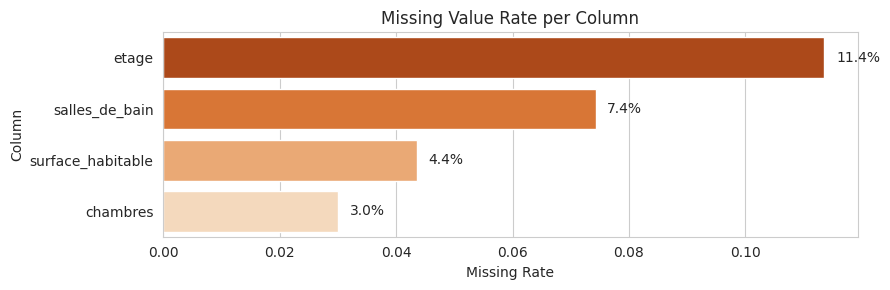

In [4]:
# Missing values
missing = df.isnull().mean().sort_values(ascending=False)
missing_df = missing[missing > 0].reset_index()
missing_df.columns = ['Column', 'Missing Rate']

fig, ax = plt.subplots(figsize=(9, 3))
sns.barplot(data=missing_df, x='Missing Rate', y='Column', palette='Oranges_r', ax=ax)
for bar, val in zip(ax.patches, missing_df['Missing Rate']):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.1%}', va='center', fontsize=10)
ax.set_title('Missing Value Rate per Column')
plt.tight_layout(); plt.show()

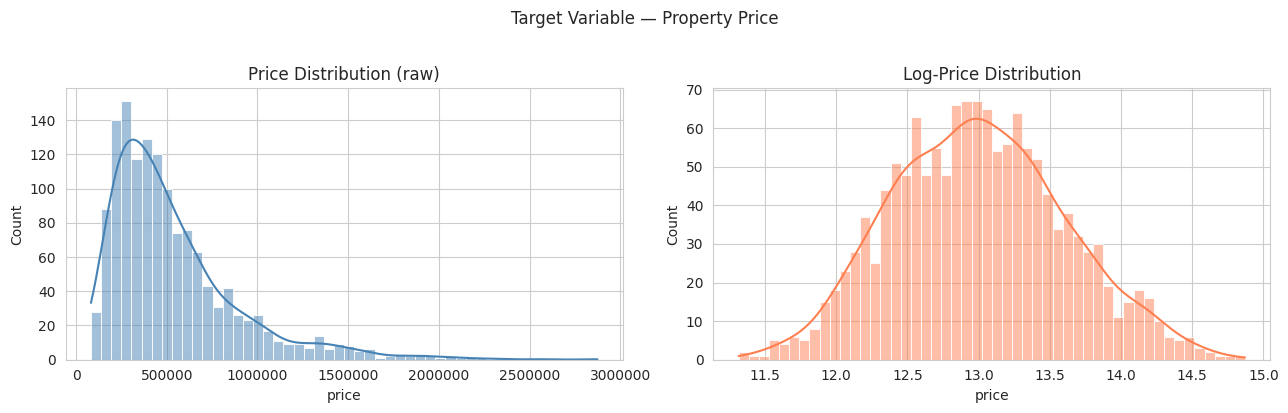

In [5]:
# Price distribution: raw vs log-transformed
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['price'], bins=50, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Price Distribution (raw)'); axes[0].ticklabel_format(style='plain', axis='x')
sns.histplot(np.log1p(df['price']), bins=50, kde=True, color='coral', ax=axes[1])
axes[1].set_title('Log-Price Distribution')
plt.suptitle('Target Variable — Property Price', y=1.02)
plt.tight_layout(); plt.show()

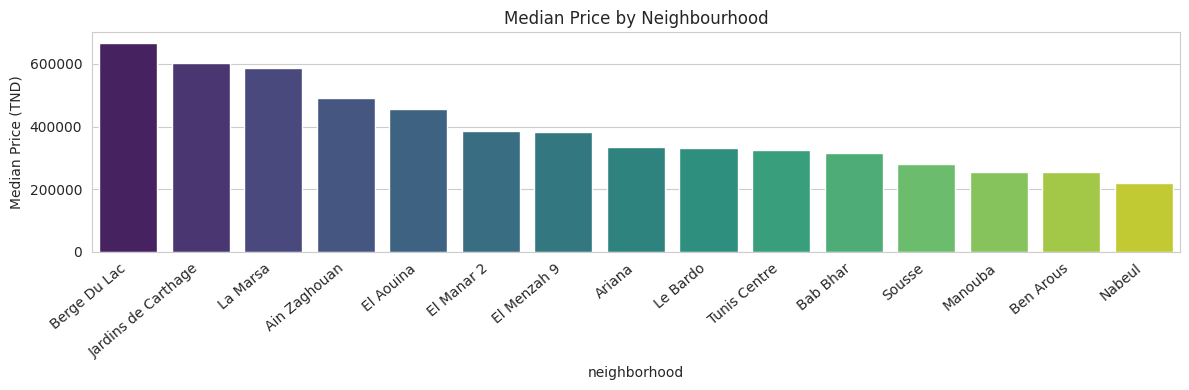

In [6]:
# Median price by neighbourhood
neigh_price = df.groupby('neighborhood')['price'].median().sort_values(ascending=False).reset_index()
plt.figure(figsize=(12, 4))
sns.barplot(data=neigh_price, x='neighborhood', y='price', palette='viridis')
plt.title('Median Price by Neighbourhood')
plt.xticks(rotation=40, ha='right'); plt.ylabel('Median Price (TND)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout(); plt.show()

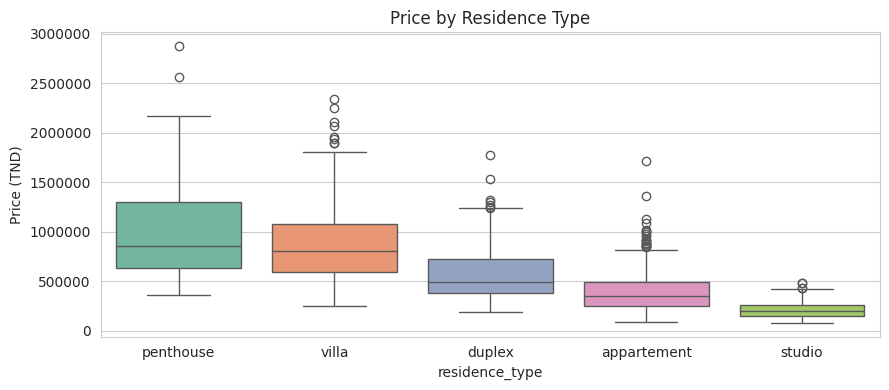

In [7]:
# Price by residence type
plt.figure(figsize=(9, 4))
order = df.groupby('residence_type')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='residence_type', y='price', order=order, palette='Set2')
plt.title('Price by Residence Type'); plt.ylabel('Price (TND)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout(); plt.show()

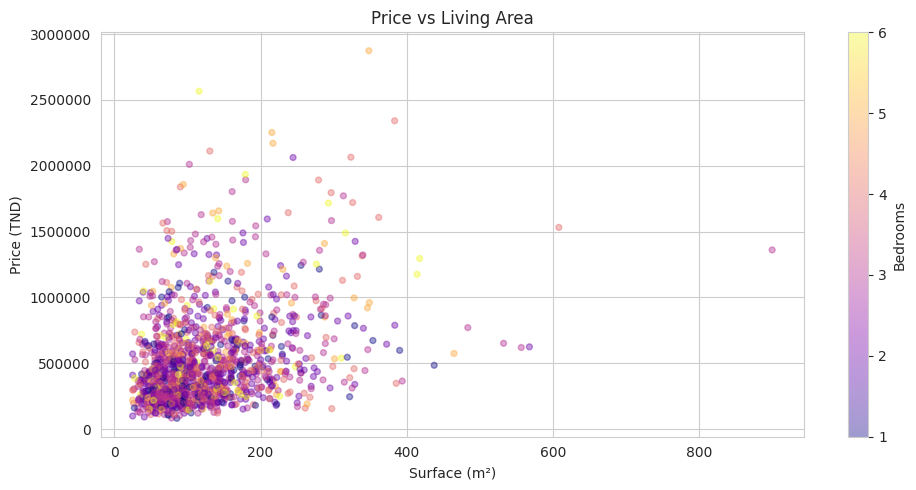

In [8]:
# Surface vs Price
plt.figure(figsize=(10, 5))
sc = plt.scatter(df['surface_habitable'], df['price'],
                 c=df['chambres'], cmap='plasma', alpha=0.4, s=18)
plt.colorbar(sc, label='Bedrooms')
plt.title('Price vs Living Area'); plt.xlabel('Surface (m²)'); plt.ylabel('Price (TND)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout(); plt.show()

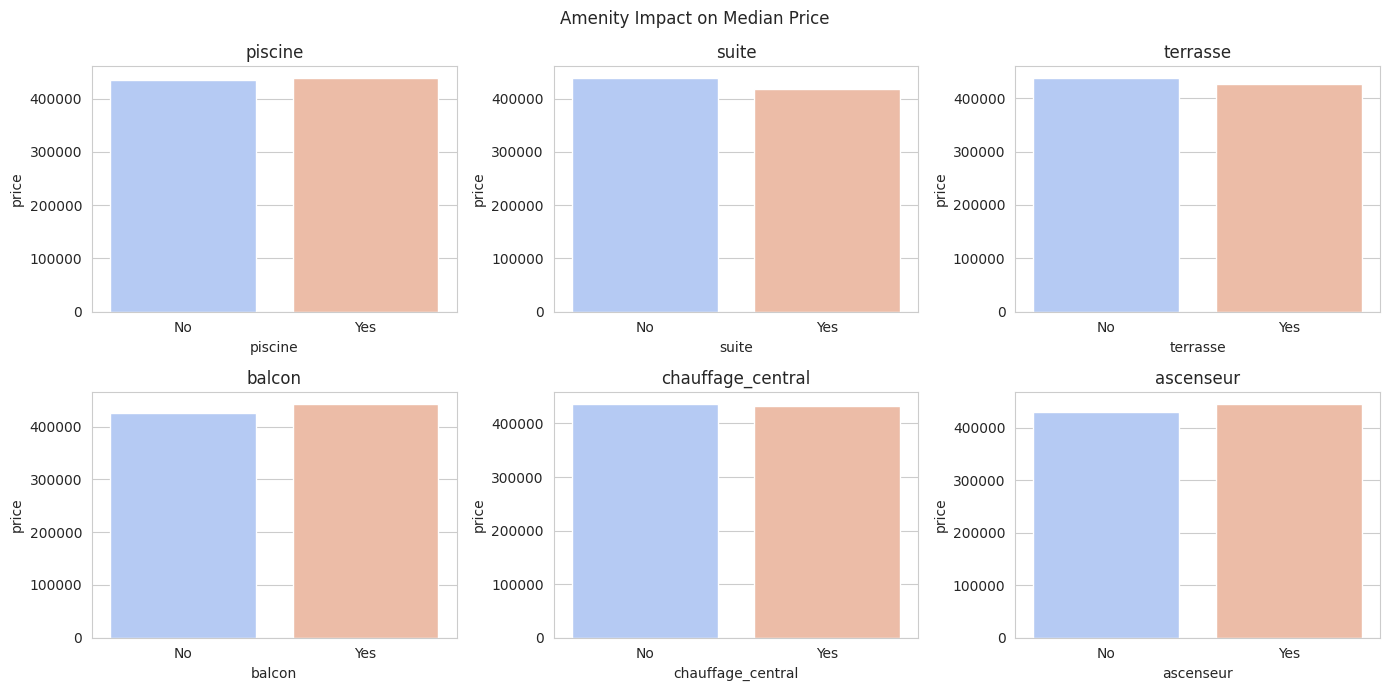

In [9]:
# Amenity impact on median price
amenities = ['piscine', 'suite', 'terrasse', 'balcon', 'chauffage_central', 'ascenseur']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.flatten(), amenities):
    sns.barplot(data=df, x=feat, y='price', palette='coolwarm',
                order=[0,1], ax=ax, estimator=np.median, ci=None)
    ax.set_title(feat); ax.set_xticklabels(['No','Yes'])
    ax.ticklabel_format(style='plain', axis='y')
plt.suptitle('Amenity Impact on Median Price')
plt.tight_layout(); plt.show()

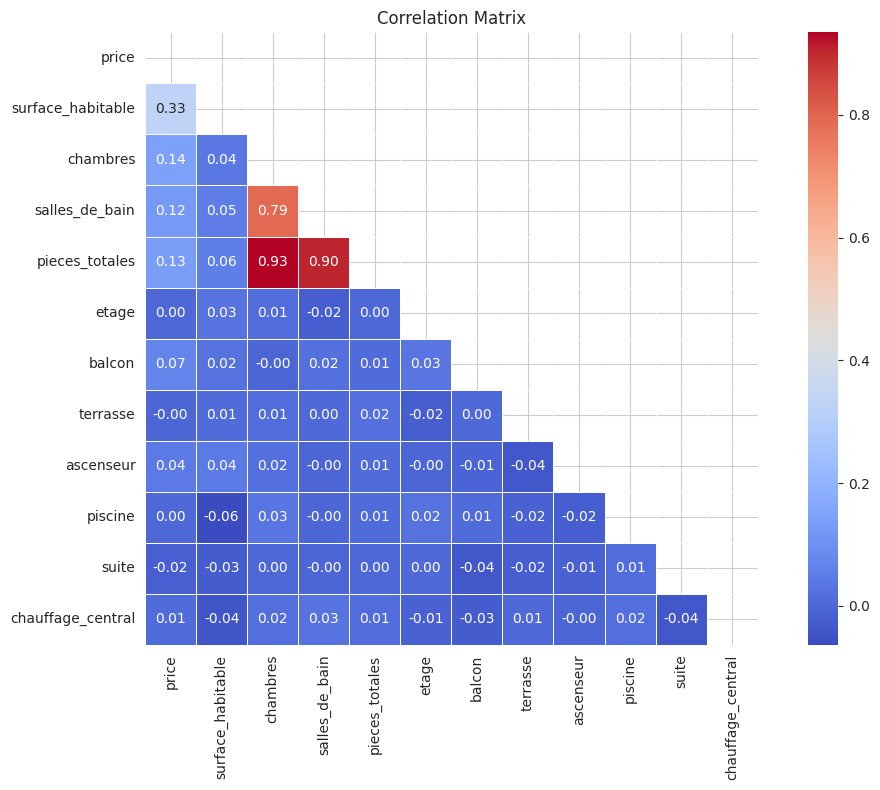

In [10]:
# Correlation matrix
num_df = df.select_dtypes(include=np.number).dropna()
corr = num_df.corr()
plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, square=True)
plt.title('Correlation Matrix')
plt.tight_layout(); plt.show()

## 4 · Data Preparation

Steps:
1. **Impute** missing values with column medians
2. **Remove outliers** using domain-knowledge bounds
3. **Engineer features**: `space_per_room`, `luxury_score`, `neigh_price_index`, `log_price`
4. **Encode** categoricals (ordinal + one-hot)
5. **Split** 70 / 15 / 15 (train / val / test)
6. **Scale** with `StandardScaler` (fitted on train only — prevents data leakage)

In [11]:
df_clean = df.copy()

# Impute medians
for col in ['chambres', 'salles_de_bain', 'etage', 'surface_habitable']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
df_clean['cuisine_type'] = df_clean['cuisine_type'].fillna('non equipee')

# Outlier removal
before = len(df_clean)
df_clean = df_clean[(df_clean['price'].between(60_000, 2_500_000)) &
                    (df_clean['surface_habitable'].between(20, 500)) &
                    (df_clean['chambres'] <= 8) &
                    (df_clean['pieces_totales'] <= 15)].reset_index(drop=True)
print(f"Rows kept: {len(df_clean)} / {before}  ({before - len(df_clean)} removed)")

Rows kept: 1393 / 1400  (7 removed)


In [12]:
# Feature engineering
df_clean['space_per_room']    = df_clean['surface_habitable'] / (df_clean['chambres'] + df_clean['salles_de_bain'] + 1)
df_clean['luxury_score']      = df_clean[['balcon','terrasse','ascenseur','piscine','suite','chauffage_central']].sum(axis=1)
neigh_median                  = df_clean.groupby('neighborhood')['price'].median()
df_clean['neigh_price_index'] = df_clean['neighborhood'].map(neigh_median)
df_clean['log_price']         = np.log1p(df_clean['price'])

# Price tier labels for classification (0=Low, 1=Medium, 2=High, 3=Luxury)
df_clean['price_tier'] = pd.cut(df_clean['price'],
                                bins=[0, 200_000, 500_000, 1_000_000, np.inf],
                                labels=[0, 1, 2, 3]).astype(int)

tier_labels = {0:'Low (<200k)', 1:'Medium (200-500k)', 2:'High (500k-1M)', 3:'Luxury (>1M)'}
print(df_clean['price_tier'].map(tier_labels).value_counts().sort_index())

price_tier
High (500k-1M)       433
Low (<200k)          133
Luxury (>1M)         137
Medium (200-500k)    690
Name: count, dtype: int64


In [13]:
# Encoding and feature matrix
df_clean['cuisine_encoded'] = df_clean['cuisine_type'].map(
    {'equipee':3, 'semi-equipee':2, 'non equipee':1, 'Unknown':0}).fillna(0)
df_clean = pd.get_dummies(df_clean, columns=['residence_type'], prefix='type', drop_first=False)

y_reg = df_clean['log_price'].values
y_clf = df_clean['price_tier'].values
X = df_clean.drop(columns=['neighborhood','cuisine_type','price','log_price','price_tier'], errors='ignore')
print("Feature matrix:", X.shape)

Feature matrix: (1393, 20)


In [14]:
# Train / Val / Test split  (70 / 15 / 15)
X_tv, X_test, y_tv, y_test_reg = train_test_split(X, y_reg, test_size=0.15, random_state=42)
X_train, X_val, y_train_reg, y_val_reg = train_test_split(X_tv, y_tv, test_size=0.15/0.85, random_state=42)

X_tv_c, X_test_c, y_tv_c, y_test_clf = train_test_split(X, y_clf, test_size=0.15, random_state=42, stratify=y_clf)
X_train_c, X_val_c, y_train_clf, y_val_clf = train_test_split(X_tv_c, y_tv_c, test_size=0.15/0.85, random_state=42, stratify=y_tv_c)

# Scale (distance-based models only)
scaler_reg = StandardScaler()
X_train_sc = scaler_reg.fit_transform(X_train)
X_val_sc   = scaler_reg.transform(X_val)
X_test_sc  = scaler_reg.transform(X_test)

scaler_clf = StandardScaler()
X_train_c_sc = scaler_clf.fit_transform(X_train_c)
X_val_c_sc   = scaler_clf.transform(X_val_c)
X_test_c_sc  = scaler_clf.transform(X_test_c)

print(f"Train: {len(X_train)}  |  Val: {len(X_val)}  |  Test: {len(X_test)}")

Train: 975  |  Val: 209  |  Test: 209


## 5 · Regression — Predicting Exact Price

Three models are compared: **KNN**, **Decision Tree**, and **Random Forest**.  
All predictions are made on log-price then back-transformed to TND for evaluation (R² and RMSE).

In [15]:
def eval_reg(y_true_log, y_pred_log):
    y_true, y_pred = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {'R2': round(r2_score(y_true, y_pred), 3),
            'RMSE': int(np.sqrt(mean_squared_error(y_true, y_pred)))}

def plot_pred_vs_actual(y_true_log, y_pred_log, title, ax):
    y_true, y_pred = np.expm1(y_true_log), np.expm1(y_pred_log)
    ax.scatter(y_true, y_pred, alpha=0.4, color='steelblue', s=18)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', lw=2, label='Perfect')
    ax.set_xlabel('Actual (TND)'); ax.set_ylabel('Predicted (TND)')
    ax.set_title(title); ax.ticklabel_format(style='plain', axis='both'); ax.legend()

### 5.1 KNN Regressor
Predicts price by averaging the log-prices of the 10 nearest neighbours. Requires feature scaling. Can struggle in high-dimensional spaces.

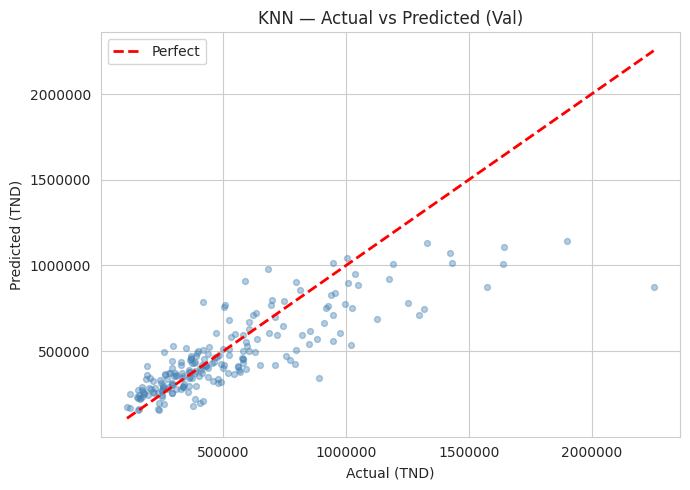

{'R2': 0.641, 'RMSE': 208440}


In [16]:
knn_reg = KNeighborsRegressor(n_neighbors=10)
knn_reg.fit(X_train_sc, y_train_reg)
knn_val_metrics = eval_reg(y_val_reg, knn_reg.predict(X_val_sc))

fig, ax = plt.subplots(figsize=(7, 5))
plot_pred_vs_actual(y_val_reg, knn_reg.predict(X_val_sc), 'KNN — Actual vs Predicted (Val)', ax)
plt.tight_layout(); plt.show()
print(knn_val_metrics)

### 5.2 Decision Tree
Splits the feature space using if/then rules that minimise MSE. Scale-invariant, but prone to overfitting — depth capped at 12.

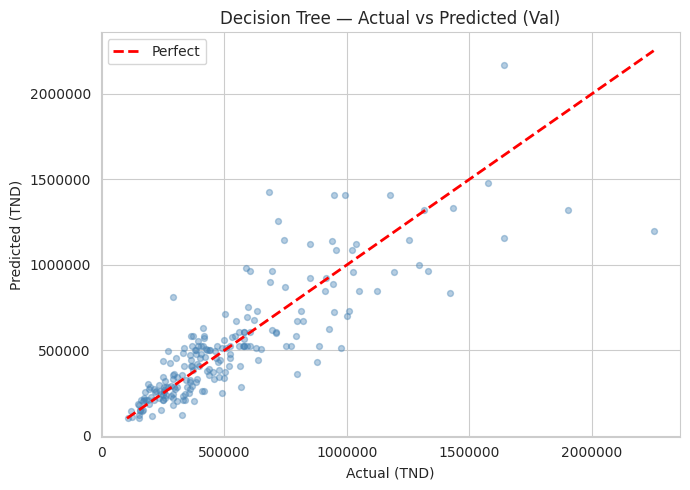

{'R2': 0.696, 'RMSE': 192046}


In [17]:
dt_reg = DecisionTreeRegressor(max_depth=12, random_state=42)
dt_reg.fit(X_train, y_train_reg)
dt_val_metrics = eval_reg(y_val_reg, dt_reg.predict(X_val))

fig, ax = plt.subplots(figsize=(7, 5))
plot_pred_vs_actual(y_val_reg, dt_reg.predict(X_val), 'Decision Tree — Actual vs Predicted (Val)', ax)
plt.tight_layout(); plt.show()
print(dt_val_metrics)

### 5.3 Random Forest
Ensemble of 300 decision trees. Reduces the variance of a single tree by averaging predictions across many decorrelated trees.

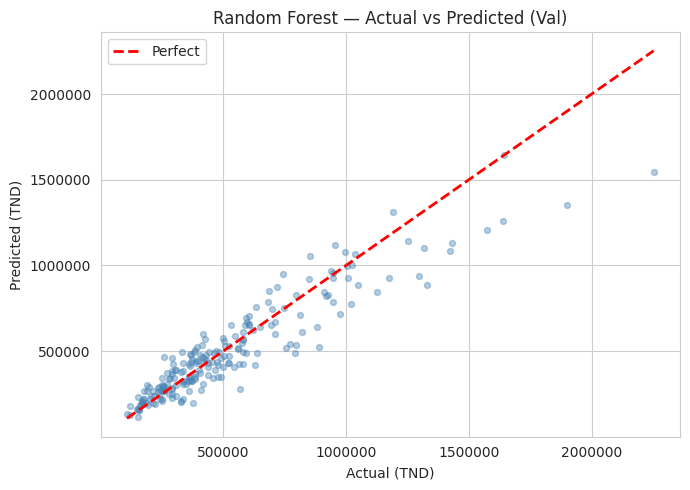

{'R2': 0.852, 'RMSE': 134005}


In [18]:
rf_reg = RandomForestRegressor(n_estimators=300, max_depth=20, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train_reg)
rf_val_metrics = eval_reg(y_val_reg, rf_reg.predict(X_val))

fig, ax = plt.subplots(figsize=(7, 5))
plot_pred_vs_actual(y_val_reg, rf_reg.predict(X_val), 'Random Forest — Actual vs Predicted (Val)', ax)
plt.tight_layout(); plt.show()
print(rf_val_metrics)

### 5.4 Regression Benchmark & Test Evaluation

In [19]:
# Validation comparison
reg_val_df = pd.DataFrame([
    {'Model': 'KNN (k=10)',     **knn_val_metrics},
    {'Model': 'Decision Tree',  **dt_val_metrics},
    {'Model': 'Random Forest',  **rf_val_metrics},
]).sort_values('R2', ascending=False).reset_index(drop=True)
display(reg_val_df)

# Test set evaluation on best model
best_reg_name  = reg_val_df.iloc[0]['Model']
best_reg_model = {'KNN (k=10)': knn_reg, 'Decision Tree': dt_reg, 'Random Forest': rf_reg}[best_reg_name]
best_reg_Xte   = X_test_sc if best_reg_name == 'KNN (k=10)' else X_test
y_pred_test_log = best_reg_model.predict(best_reg_Xte)
test_metrics = eval_reg(y_test_reg, y_pred_test_log)

print(f"Best model: {best_reg_name}")
print(f"Test R²   = {test_metrics['R2']:.3f}  |  Test RMSE = {test_metrics['RMSE']:,} TND")

,Model,R2,RMSE
0,Random Forest,0.852,134005
1,Decision Tree,0.696,192046
2,KNN (k=10),0.641,208440


Best model: Random Forest
Test R²   = 0.747  |  Test RMSE = 154,936 TND


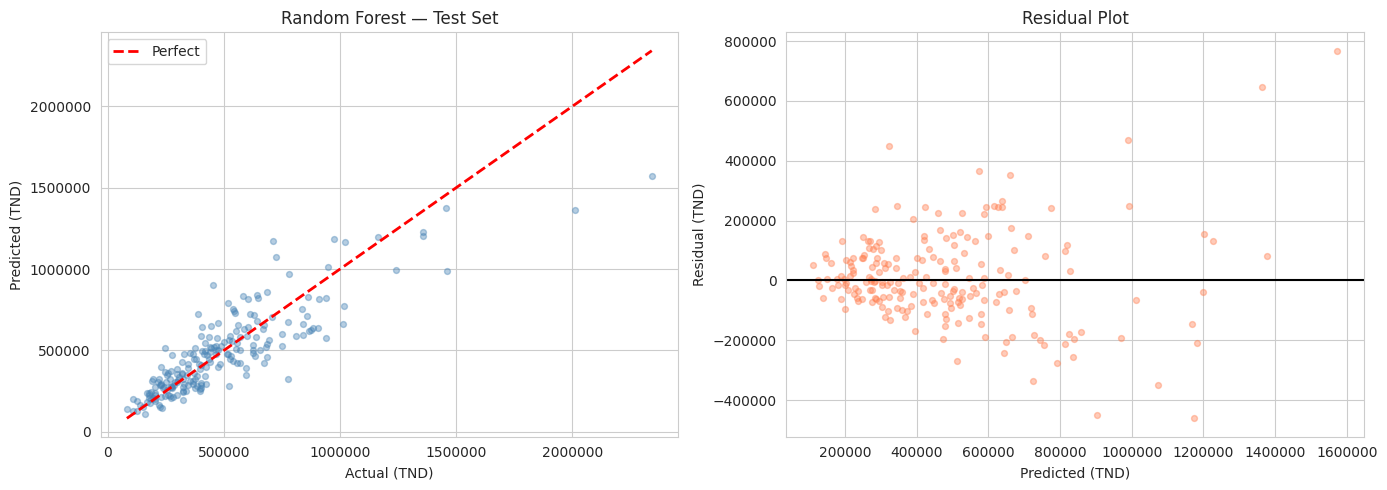

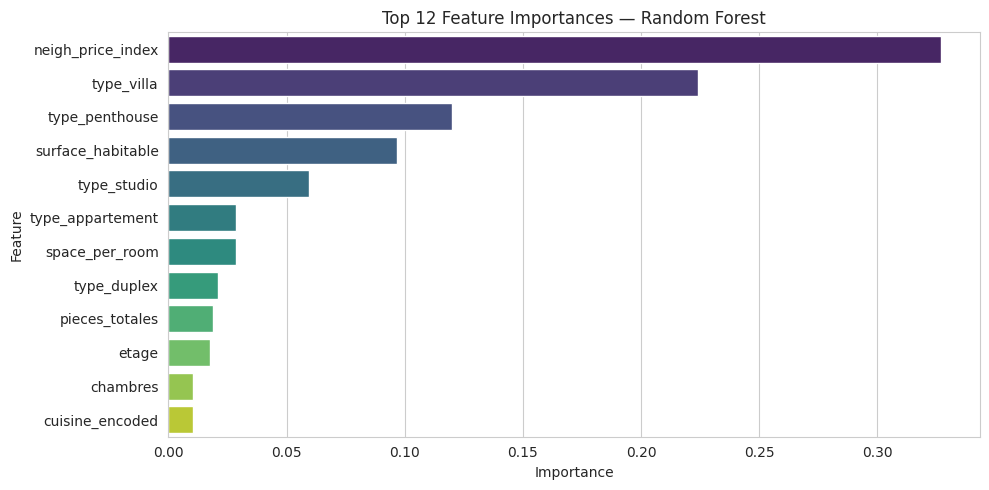

In [20]:
# Actual vs Predicted + Residual plots (test set)
y_pred_tnd = np.expm1(y_pred_test_log)
y_true_tnd = np.expm1(y_test_reg)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_pred_vs_actual(y_test_reg, y_pred_test_log, f'{best_reg_name} — Test Set', axes[0])
axes[1].scatter(y_pred_tnd, y_true_tnd - y_pred_tnd, alpha=0.4, color='coral', s=18)
axes[1].axhline(0, color='black', lw=1.5)
axes[1].set_xlabel('Predicted (TND)'); axes[1].set_ylabel('Residual (TND)')
axes[1].set_title('Residual Plot'); axes[1].ticklabel_format(style='plain', axis='both')
plt.tight_layout(); plt.show()

# Feature importances
imp = pd.DataFrame({'Feature': X_train.columns, 'Importance': rf_reg.feature_importances_})
imp = imp.sort_values('Importance', ascending=False).head(12)
plt.figure(figsize=(10, 5))
sns.barplot(data=imp, y='Feature', x='Importance', palette='viridis')
plt.title('Top 12 Feature Importances — Random Forest')
plt.tight_layout(); plt.show()

## 6 · Classification — Predicting Price Tier

Properties are assigned to one of four tiers: **Low** (<200k), **Medium** (200-500k), **High** (500k-1M), **Luxury** (>1M TND).  
Two classifiers are compared: **Naive Bayes** (baseline) and **Random Forest**.

In [21]:
def eval_clf(y_true, y_pred):
    return {
        'Accuracy':  round(accuracy_score(y_true, y_pred), 3),
        'Precision': round(precision_score(y_true, y_pred, average='weighted', zero_division=0), 3),
        'Recall':    round(recall_score(y_true, y_pred, average='weighted', zero_division=0), 3),
        'F1':        round(f1_score(y_true, y_pred, average='weighted', zero_division=0), 3),
    }

def plot_cm(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Low','Med','High','Lux'],
                yticklabels=['Low','Med','High','Lux'])
    ax.set_title(title); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

### 6.1 Naive Bayes
Assumes all features are independent — a strong assumption that is violated here (e.g. bedrooms and total rooms are highly correlated). Serves as a diagnostic baseline.

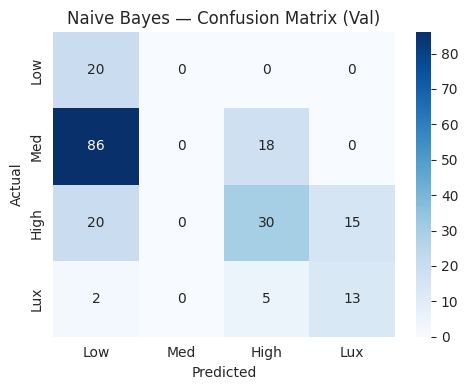

{'Accuracy': 0.301, 'Precision': 0.235, 'Recall': 0.301, 'F1': 0.236}


In [22]:
nb_clf = GaussianNB()
nb_clf.fit(X_train_c_sc, y_train_clf)
nb_val_pred    = nb_clf.predict(X_val_c_sc)
nb_val_metrics = eval_clf(y_val_clf, nb_val_pred)

fig, ax = plt.subplots(figsize=(5, 4))
plot_cm(y_val_clf, nb_val_pred, 'Naive Bayes — Confusion Matrix (Val)', ax)
plt.tight_layout(); plt.show()
print(nb_val_metrics)

### 6.2 Random Forest Classifier
Same ensemble logic as the regressor. No feature scaling needed, handles class imbalance naturally, and exploits feature interactions through split-based partitioning.

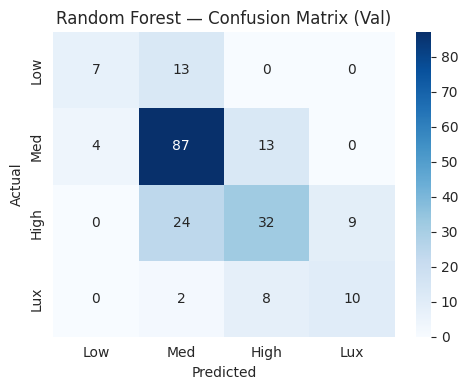

{'Accuracy': 0.651, 'Precision': 0.643, 'Recall': 0.651, 'F1': 0.637}


In [23]:
rf_clf = RandomForestClassifier(n_estimators=300, max_depth=20, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_c, y_train_clf)
rf_val_pred_clf    = rf_clf.predict(X_val_c)
rf_val_metrics_clf = eval_clf(y_val_clf, rf_val_pred_clf)

fig, ax = plt.subplots(figsize=(5, 4))
plot_cm(y_val_clf, rf_val_pred_clf, 'Random Forest — Confusion Matrix (Val)', ax)
plt.tight_layout(); plt.show()
print(rf_val_metrics_clf)

### 6.3 Classification Benchmark & Test Evaluation

In [24]:
# Validation comparison
clf_val_df = pd.DataFrame([
    {'Model': 'Naive Bayes',   **nb_val_metrics},
    {'Model': 'Random Forest', **rf_val_metrics_clf},
]).sort_values('F1', ascending=False).reset_index(drop=True)
display(clf_val_df)

# Test set evaluation on best model
best_clf_name  = clf_val_df.iloc[0]['Model']
best_clf_model = {'Naive Bayes': nb_clf, 'Random Forest': rf_clf}[best_clf_name]
best_clf_Xte   = X_test_c_sc if best_clf_name == 'Naive Bayes' else X_test_c
y_pred_test_clf = best_clf_model.predict(best_clf_Xte)
test_clf = eval_clf(y_test_clf, y_pred_test_clf)

print(f"Best model: {best_clf_name}")
print(f"Accuracy={test_clf['Accuracy']}  Precision={test_clf['Precision']}  Recall={test_clf['Recall']}  F1={test_clf['F1']}")

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.651,0.643,0.651,0.637
1,Naive Bayes,0.301,0.235,0.301,0.236


Best model: Random Forest
Accuracy=0.746  Precision=0.75  Recall=0.746  F1=0.745


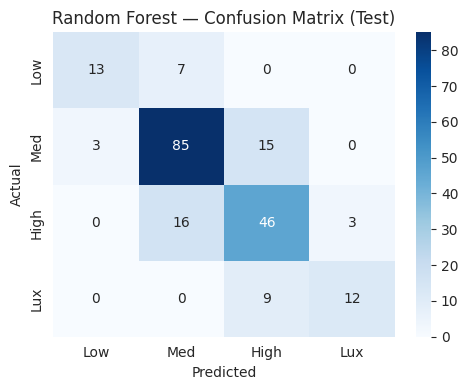

              precision    recall  f1-score   support

         Low       0.81      0.65      0.72        20
      Medium       0.79      0.83      0.81       103
        High       0.66      0.71      0.68        65
      Luxury       0.80      0.57      0.67        21

    accuracy                           0.75       209
   macro avg       0.76      0.69      0.72       209
weighted avg       0.75      0.75      0.75       209



In [25]:
fig, ax = plt.subplots(figsize=(5, 4))
plot_cm(y_test_clf, y_pred_test_clf, f'{best_clf_name} — Confusion Matrix (Test)', ax)
plt.tight_layout(); plt.show()

print(classification_report(y_test_clf, y_pred_test_clf,
                             target_names=['Low','Medium','High','Luxury'], zero_division=0))

## 7 · Live Demo — Price Prediction

Define a property, run both the best regression and classification models, and get a price estimate + tier.

In [26]:
sample = {
    'surface_habitable': 120.0, 'chambres': 3.0, 'salles_de_bain': 2.0,
    'pieces_totales': 6.0, 'etage': 2.0,
    'balcon': 1, 'terrasse': 0, 'ascenseur': 1,
    'piscine': 0, 'suite': 0, 'chauffage_central': 0,
    'neighborhood': 'El Manar 2', 'residence_type': 'appartement', 'cuisine_type': 'equipee',
}

# Engineer features
space_per_room   = sample['surface_habitable'] / (sample['chambres'] + sample['salles_de_bain'] + 1)
luxury_score     = sum(sample[k] for k in ['balcon','terrasse','ascenseur','piscine','suite','chauffage_central'])
neigh_price_idx  = float(neigh_median.get(sample['neighborhood'], neigh_median.median()))
cuisine_enc      = {'equipee':3,'semi-equipee':2,'non equipee':1,'Unknown':0}.get(sample['cuisine_type'], 0)
res_ohe          = {f"type_{rt}": int(sample['residence_type'] == rt)
                    for rt in ['appartement','duplex','penthouse','studio','villa']}

demo_row = {
    'surface_habitable': sample['surface_habitable'], 'chambres': sample['chambres'],
    'salles_de_bain': sample['salles_de_bain'], 'pieces_totales': sample['pieces_totales'],
    'etage': sample['etage'], 'balcon': sample['balcon'], 'terrasse': sample['terrasse'],
    'ascenseur': sample['ascenseur'], 'piscine': sample['piscine'],
    'suite': sample['suite'], 'chauffage_central': sample['chauffage_central'],
    'cuisine_encoded': cuisine_enc, 'space_per_room': space_per_room,
    'luxury_score': luxury_score, 'neigh_price_index': neigh_price_idx,
    **res_ohe,
}
demo_df = pd.DataFrame([demo_row])
for col in X.columns:
    if col not in demo_df.columns:
        demo_df[col] = 0
demo_df = demo_df[X.columns]

# Predict
log_price  = best_reg_model.predict(scaler_reg.transform(demo_df) if best_reg_name == 'KNN (k=10)' else demo_df)[0]
price_tnd  = np.expm1(log_price)
tier_idx   = best_clf_model.predict(scaler_clf.transform(demo_df) if best_clf_name == 'Naive Bayes' else demo_df)[0]
tier_names = {0:'Low (<200k TND)', 1:'Medium (200-500k TND)', 2:'High (500k-1M TND)', 3:'Luxury (>1M TND)'}

print(f"Property : 3-bed apartment · 120 m² · El Manar 2 · Floor 2 · Equipped kitchen")
print(f"Price    : {price_tnd:,.0f} TND   (model: {best_reg_name})")
print(f"Tier     : {tier_names[tier_idx]}   (model: {best_clf_name})")

Property : 3-bed apartment · 120 m² · El Manar 2 · Floor 2 · Equipped kitchen
Price    : 299,470 TND   (model: Random Forest)
Tier     : Medium (200-500k TND)   (model: Random Forest)
